In [9]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


x_train = torch.linspace(-2*torch.pi, 2*torch.pi, 500).unsqueeze(1).to(device)
y_train = torch.sin(x_train) + torch.sin(5*x_train)


def plot_results(model, epoch, title):
    model.eval()
    with torch.no_grad():
        preds = model(x_train).cpu().numpy()

    x_np = x_train.cpu().numpy()
    y_true = np.sin(x_np) + np.sin(5*x_np)
    y_sin = np.sin(x_np)

    plt.figure(figsize=(10, 5))
    plt.plot(x_np, y_true, label='sin(x) + sin(5x)')
    plt.plot(x_np, y_sin, label='sin(x)', alpha=0.5)
    plt.scatter(x_np, preds, label='pred', color='red', s=5)
    plt.title(f"{title} (Epoch {epoch})")
    plt.legend()
    plt.show()
    model.train()

Архитектура обычной нейросети:
SimpleNN(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=256, bias=True)
    (1): Tanh()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): Tanh()
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


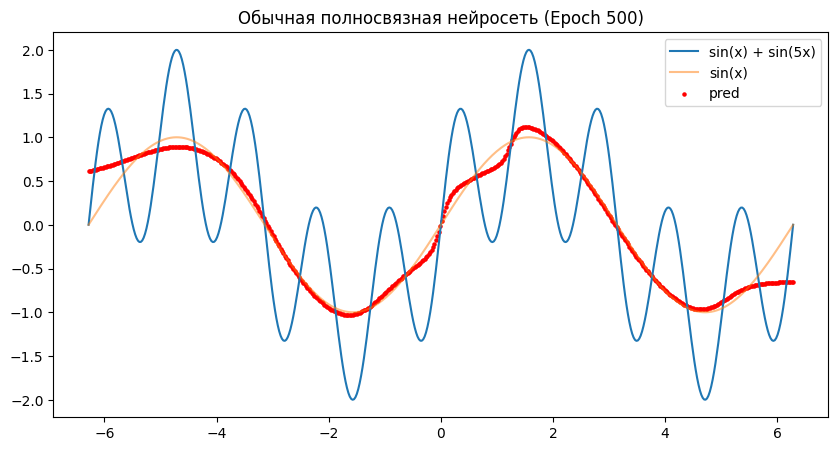

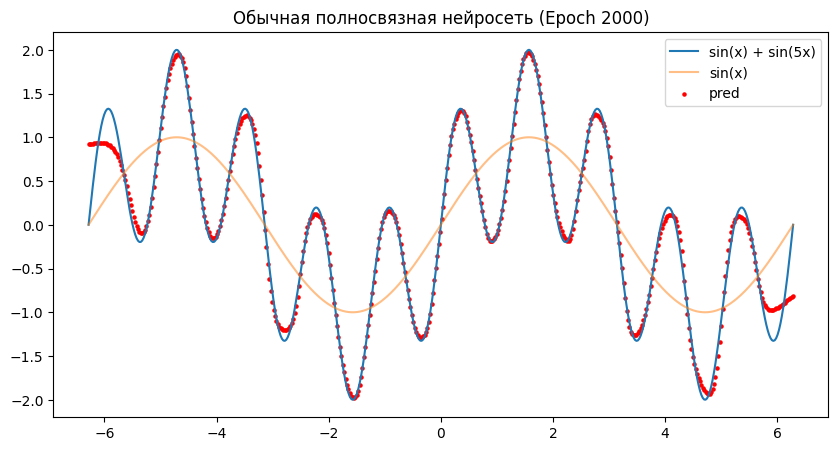

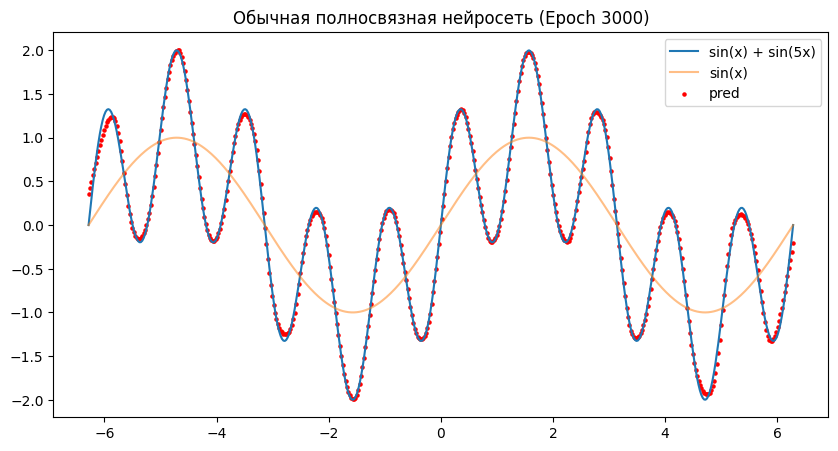

In [10]:
import numpy as np

class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.net(x)


model_simple = SimpleNN().to(device)
optimizer = torch.optim.Adam(model_simple.parameters(), lr=0.001)
criterion = nn.MSELoss()

print("Архитектура обычной нейросети:")
print(model_simple)

epochs_to_plot = [500, 2000, 3000]

for epoch in range(1, 3001):
    optimizer.zero_grad()
    preds = model_simple(x_train)
    loss = criterion(preds, y_train)
    loss.backward()
    optimizer.step()

    if epoch in epochs_to_plot:
        plot_results(model_simple, epoch, "Обычная полносвязная нейросеть")

Архитектура нейросети с Фурье-кодированием:
FourierNN(
  (fourier_embedding): FourierFeatureEmbedding()
  (net): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): Tanh()
    (2): Linear(in_features=256, out_features=1, bias=True)
  )
)


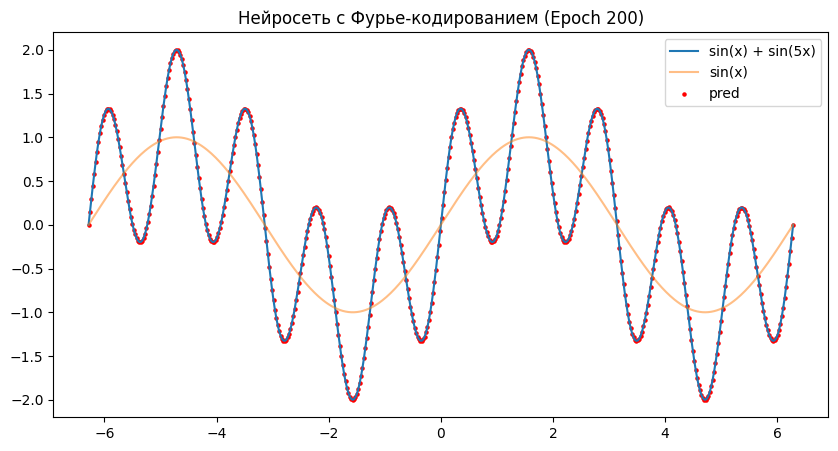

In [11]:

class FourierFeatureEmbedding(nn.Module):
    def __init__(self, in_dim, mapping_size, scale=10.0):
        super().__init__()

        self.B = nn.Parameter(torch.randn(in_dim, mapping_size) * scale * 2 * torch.pi, requires_grad=False)

    def forward(self, v):
        proj = torch.matmul(v, self.B)

        return torch.cat([torch.cos(proj), torch.sin(proj)], dim=-1)

class FourierNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.fourier_embedding = FourierFeatureEmbedding(in_dim=1, mapping_size=128, scale=10.0)

        self.net = nn.Sequential(
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.fourier_embedding(x)
        return self.net(x)


model_fourier = FourierNN().to(device)
optimizer_fourier = torch.optim.Adam(model_fourier.parameters(), lr=0.001)

print("Архитектура нейросети с Фурье-кодированием:")
print(model_fourier)

for epoch in range(1, 201):
    optimizer_fourier.zero_grad()
    preds = model_fourier(x_train)
    loss = criterion(preds, y_train)
    loss.backward()
    optimizer_fourier.step()

plot_results(model_fourier, 200, "Нейросеть с Фурье-кодированием")

Архитектура нейросети с Фурье (без Tanh):
FourierNN_NoAct(
  (fourier_embedding): FourierFeatureEmbedding()
  (net): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): Linear(in_features=256, out_features=1, bias=True)
  )
)


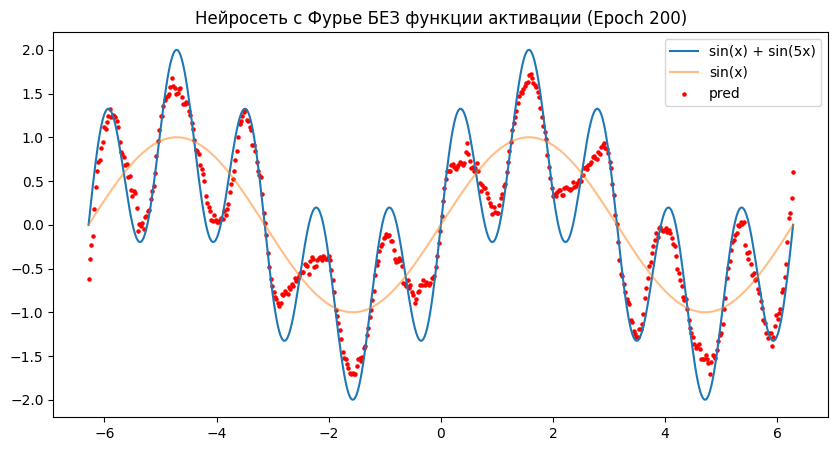

In [12]:
class FourierNN_NoAct(nn.Module):
    def __init__(self):
        super().__init__()
        self.fourier_embedding = FourierFeatureEmbedding(in_dim=1, mapping_size=128, scale=10.0)


        self.net = nn.Sequential(
            nn.Linear(256, 256),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.fourier_embedding(x)
        return self.net(x)


model_no_act = FourierNN_NoAct().to(device)
optimizer_no_act = torch.optim.Adam(model_no_act.parameters(), lr=0.001)

print("Архитектура нейросети с Фурье (без Tanh):")
print(model_no_act)

for epoch in range(1, 201):
    optimizer_no_act.zero_grad()
    preds = model_no_act(x_train)
    loss = criterion(preds, y_train)
    loss.backward()
    optimizer_no_act.step()

plot_results(model_no_act, 200, "Нейросеть с Фурье БЕЗ функции активации")